# **Week 9 – House Sales Data Understanding, Cleaning & Feature Engineering**

Step 1: Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Step 2: Upload the dataset

In [2]:
df = pd.read_csv("/content/drive/MyDrive/EDA-Skill/kc_house_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [4]:
df.tail()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287
21612,1523300157,20141015T000000,325000.0,2,0.75,1020,1076,2.0,0,0,...,7,1020,0,2008,0,98144,47.5941,-122.299,1020,1357


Step 3: Understand the dataset

In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (21613, 21)

Column Names:
['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grad

In [6]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [7]:
print("Numerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Columns:")
print(df.select_dtypes(include="object").columns.tolist())

Numerical Columns:
['id', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

Categorical Columns:
['date']


Step 4: Standardize column names

In [8]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Standardized Column Names:")
print(df.columns.tolist())

Standardized Column Names:
['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


Step 5: Check missing values

In [9]:
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

display(missing_values)

,Missing_Count,Missing_Percentage
id,0,0.0
date,0,0.0
price,0,0.0
bedrooms,0,0.0
bathrooms,0,0.0
sqft_living,0,0.0
sqft_lot,0,0.0
floors,0,0.0
waterfront,0,0.0
view,0,0.0


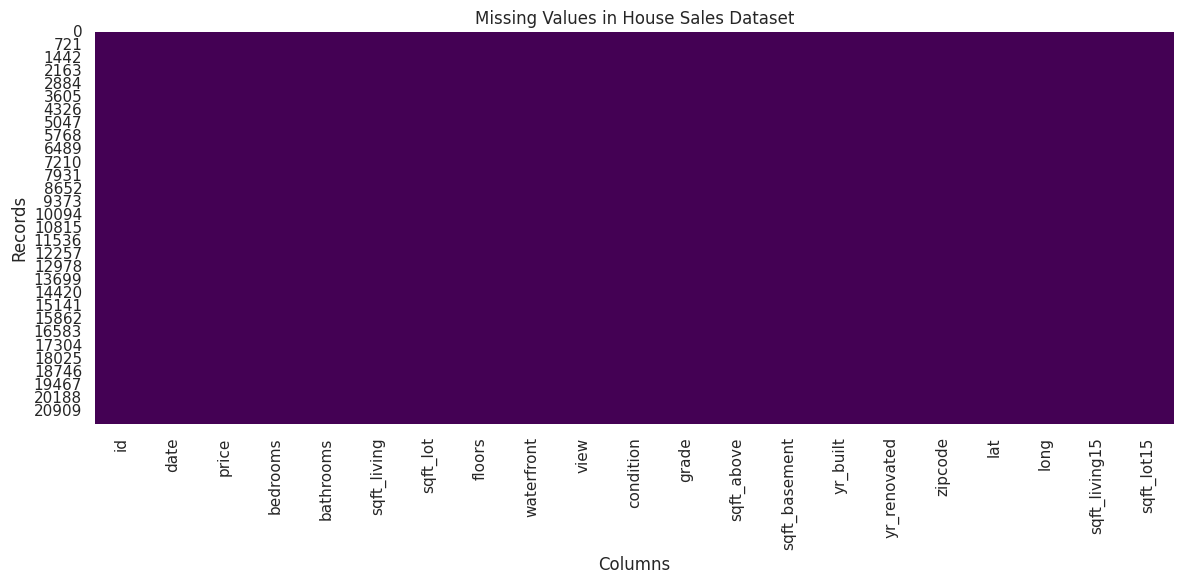

In [10]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values in House Sales Dataset")
plt.xlabel("Columns")
plt.ylabel("Records")

plt.tight_layout()
plt.show()

Step 6: Remove duplicate records

In [11]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


Step 7: Convert data types

In [12]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print(df["date"].dtype)

datetime64[ns]


In [13]:
print("Earliest Sale Date:", df["date"].min())
print("Latest Sale Date:", df["date"].max())

Earliest Sale Date: 2014-05-02 00:00:00
Latest Sale Date: 2015-05-27 00:00:00


In [14]:
numeric_columns = [
    "price",
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "grade",
    "sqft_above",
    "sqft_basement",
    "yr_built",
    "yr_renovated",
    "lat",
    "long",
    "sqft_living15",
    "sqft_lot15"
]

for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )

print("Data type conversion completed.")

Data type conversion completed.


Step 8: Identify invalid zero values

In [15]:
zero_columns = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "price"
]

for column in zero_columns:
    if column in df.columns:
        print(
            column,
            "Zero Values:",
            (df[column] == 0).sum()
        )

bedrooms Zero Values: 13
bathrooms Zero Values: 10
sqft_living Zero Values: 0
sqft_lot Zero Values: 0
floors Zero Values: 0
price Zero Values: 0


In [16]:
invalid_zero_columns = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot"
]

for column in invalid_zero_columns:
    if column in df.columns:
        df.loc[df[column] == 0, column] = np.nan

print("Invalid zero values converted to NaN.")

Invalid zero values converted to NaN.


Step 9: Handle missing values

In [17]:
print(df.isnull().sum())

id                0
date              0
price             0
bedrooms         13
bathrooms        10
sqft_living       0
sqft_lot          0
floors            0
waterfront        0
view              0
condition         0
grade             0
sqft_above        0
sqft_basement     0
yr_built          0
yr_renovated      0
zipcode           0
lat               0
long              0
sqft_living15     0
sqft_lot15        0
dtype: int64


Step 10: Validate property values

In [18]:
validation_columns = [
    "price",
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors"
]

for column in validation_columns:
    if column in df.columns:
        print(
            column,
            "Negative Values:",
            (df[column] < 0).sum()
        )

price Negative Values: 0
bedrooms Negative Values: 0
bathrooms Negative Values: 0
sqft_living Negative Values: 0
sqft_lot Negative Values: 0
floors Negative Values: 0


In [19]:
df = df[
    (df["price"] > 0) &
    (df["sqft_living"] > 0) &
    (df["sqft_lot"] > 0)
].copy()

print("Remaining records:", len(df))

Remaining records: 21613


Step 11: Extract temporal attributes from sale date

In [20]:
df["sale_year"] = df["date"].dt.year

In [21]:
df["sale_month"] = df["date"].dt.month

In [22]:
df["sale_quarter"] = df["date"].dt.quarter

In [23]:
df["sale_day"] = df["date"].dt.day

In [24]:
df[
    ["date", "sale_year", "sale_month", "sale_quarter", "sale_day"]
].head()

,date,sale_year,sale_month,sale_quarter,sale_day
0,2014-10-13,2014,10,4,13
1,2014-12-09,2014,12,4,9
2,2015-02-25,2015,2,1,25
3,2014-12-09,2014,12,4,9
4,2015-02-18,2015,2,1,18


Step 12: Calculate property age

In [25]:
df["property_age"] = (
    df["sale_year"] - df["yr_built"]
)

df[["sale_year", "yr_built", "property_age"]].head()

,sale_year,yr_built,property_age
0,2014,1955,59
1,2014,1951,63
2,2015,1933,82
3,2014,1965,49
4,2015,1987,28


In [26]:
print(
    "Negative Property Ages:",
    (df["property_age"] < 0).sum()
)

Negative Property Ages: 12


Step 13: Create renovation features

In [27]:
df["is_renovated"] = np.where(
    df["yr_renovated"] > 0,
    1,
    0
)

In [28]:
df["renovation_year"] = df["yr_renovated"].replace(
    0,
    np.nan
)

In [29]:
df["years_since_renovation"] = np.where(
    df["is_renovated"] == 1,
    df["sale_year"] - df["yr_renovated"],
    np.nan
)

In [30]:
df[
    [
        "yr_built",
        "yr_renovated",
        "is_renovated",
        "renovation_year",
        "years_since_renovation"
    ]
].head(10)

,yr_built,yr_renovated,is_renovated,renovation_year,years_since_renovation
0,1955,0,0,NaN,NaN
1,1951,1991,1,1991.0,23.0
2,1933,0,0,NaN,NaN
3,1965,0,0,NaN,NaN
4,1987,0,0,NaN,NaN
5,2001,0,0,NaN,NaN
6,1995,0,0,NaN,NaN
7,1963,0,0,NaN,NaN
8,1960,0,0,NaN,NaN
9,2003,0,0,NaN,NaN


In [31]:
invalid_renovation = df[
    (df["yr_renovated"] > 0) &
    (df["yr_renovated"] > df["sale_year"])
]

print("Invalid Renovation Records:", len(invalid_renovation))

Invalid Renovation Records: 6


Step 14: Calculate price per square foot

In [32]:
df["price_per_sqft_living"] = (
    df["price"] / df["sqft_living"]
)

df[
    ["price", "sqft_living", "price_per_sqft_living"]
].head()

,price,sqft_living,price_per_sqft_living
0,221900.0,1180.0,188.050847
1,538000.0,2570.0,209.338521
2,180000.0,770.0,233.766234
3,604000.0,1960.0,308.163265
4,510000.0,1680.0,303.571429


In [33]:
df["price_per_sqft_lot"] = (
    df["price"] / df["sqft_lot"]
)

df[
    ["price", "sqft_lot", "price_per_sqft_lot"]
].head()

,price,sqft_lot,price_per_sqft_lot
0,221900.0,5650.0,39.274336
1,538000.0,7242.0,74.288870
2,180000.0,10000.0,18.000000
3,604000.0,5000.0,120.800000
4,510000.0,8080.0,63.118812


Step 15: Create additional property features

In [34]:
df["total_rooms"] = (
    df["bedrooms"] + df["bathrooms"]
)

In [35]:
df["living_lot_ratio"] = (
    df["sqft_living"] / df["sqft_lot"]
)

In [36]:
df["property_age_category"] = pd.cut(
    df["property_age"],
    bins=[-1, 10, 25, 50, 100, np.inf],
    labels=[
        "New",
        "Recent",
        "Middle Aged",
        "Old",
        "Very Old"
    ]
)

In [37]:
df[
    [
        "bedrooms",
        "bathrooms",
        "total_rooms",
        "property_age",
        "property_age_category",
        "living_lot_ratio"
    ]
].head()

,bedrooms,bathrooms,total_rooms,property_age,property_age_category,living_lot_ratio
0,3.0,1.00,4.00,59,Old,0.208850
1,3.0,2.25,5.25,63,Old,0.354874
2,2.0,1.00,3.00,82,Old,0.077000
3,4.0,3.00,7.00,49,Middle Aged,0.392000
4,3.0,2.00,5.00,28,Middle Aged,0.207921


Step 16: Descriptive statistical analysis

In [38]:
analysis_columns = [
    "price",
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "property_age",
    "price_per_sqft_living",
    "price_per_sqft_lot"
]

summary_statistics = df[analysis_columns].describe()

display(summary_statistics)

,price,bedrooms,bathrooms,sqft_living,sqft_lot,property_age,price_per_sqft_living,price_per_sqft_lot
count,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000
mean,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,43.317818,264.156594,88.966710
std,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,29.375493,110.060793,94.055247
min,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,-1.000000,87.588235,0.163119
25%,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,18.000000,182.291667,33.333333
50%,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,40.000000,244.644550,59.223301
75%,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,63.000000,318.322981,107.594937
max,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,115.000000,810.138889,2027.208539


In [39]:
additional_statistics = pd.DataFrame({
    "Mean": df[analysis_columns].mean(),
    "Median": df[analysis_columns].median(),
    "Mode": df[analysis_columns].mode().iloc[0],
    "Standard Deviation": df[analysis_columns].std(),
    "Variance": df[analysis_columns].var()
})

display(additional_statistics)

,Mean,Median,Mode,Standard Deviation,Variance
price,540088.141767,450000.000000,350000.0,367127.196483,1.347824e+11
bedrooms,3.372870,3.000000,3.0,0.926657,8.586926e-01
bathrooms,2.115736,2.250000,2.5,0.768996,5.913546e-01
sqft_living,2079.899736,1910.000000,1300.0,918.440897,8.435337e+05
sqft_lot,15106.967566,7618.000000,5000.0,41420.511515,1.715659e+09
property_age,43.317818,40.000000,9.0,29.375493,8.629196e+02
price_per_sqft_living,264.156594,244.644550,250.0,110.060793,1.211338e+04
price_per_sqft_lot,88.966710,59.223301,100.0,94.055247,8.846390e+03


Step 17: Visualize house price distributions

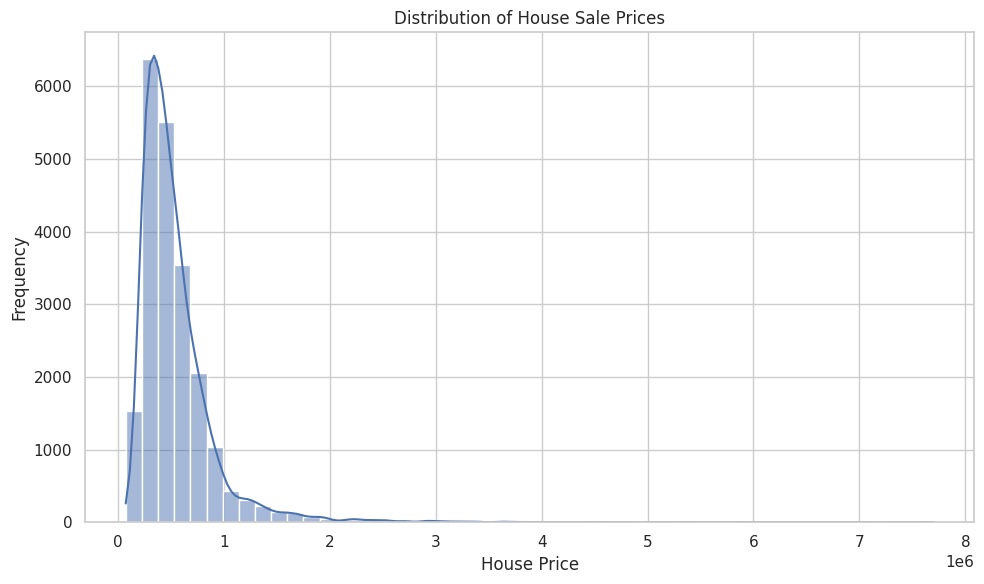

In [40]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="price",
    bins=50,
    kde=True
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

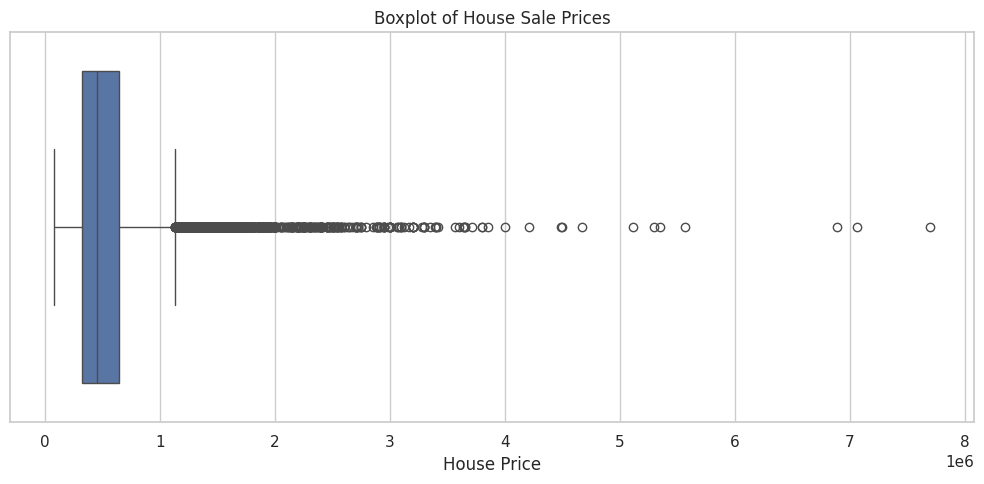

In [41]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["price"]
)

plt.title("Boxplot of House Sale Prices")
plt.xlabel("House Price")

plt.tight_layout()
plt.show()


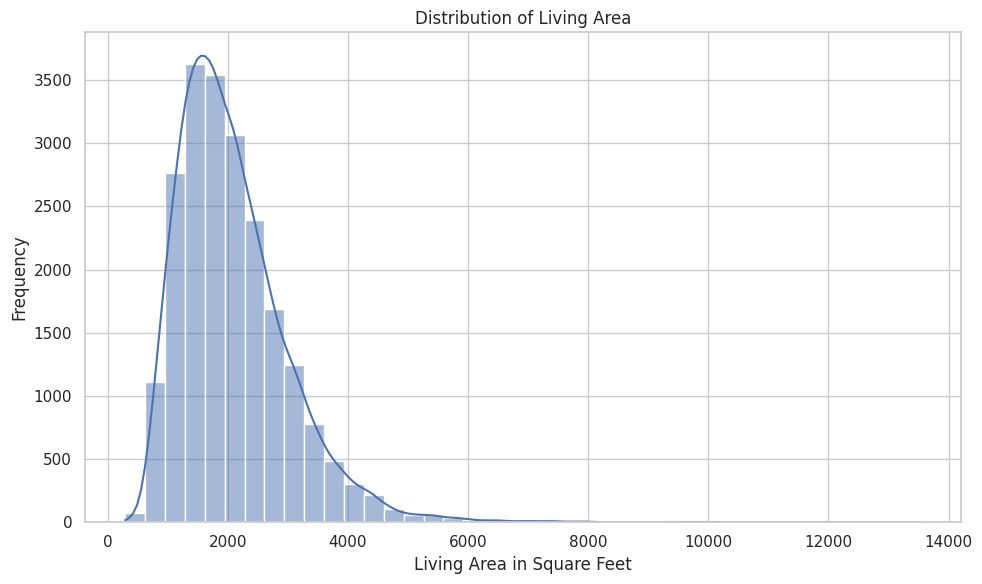

In [42]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="sqft_living",
    bins=40,
    kde=True
)

plt.title("Distribution of Living Area")
plt.xlabel("Living Area in Square Feet")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Step 18: Detect outliers using IQR

In [43]:
outlier_columns = [
    "price",
    "sqft_living",
    "sqft_lot",
    "bedrooms",
    "bathrooms",
    "price_per_sqft_living",
    "price_per_sqft_lot"
]

outlier_results = []

for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Column": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,price,321950.000000,645000.000000,323050.000000,-162625.000000,1.129575e+06,1146
1,sqft_living,1427.000000,2550.000000,1123.000000,-257.500000,4.234500e+03,572
2,sqft_lot,5040.000000,10688.000000,5648.000000,-3432.000000,1.916000e+04,2425
3,bedrooms,3.000000,4.000000,1.000000,1.500000,5.500000e+00,533
4,bathrooms,1.750000,2.500000,0.750000,0.625000,3.625000e+00,561
5,price_per_sqft_living,182.291667,318.322981,136.031315,-21.755305,5.223700e+02,708
6,price_per_sqft_lot,33.333333,107.594937,74.261603,-78.059072,2.189873e+02,1720


Step 19: Visualize outliers using boxplots

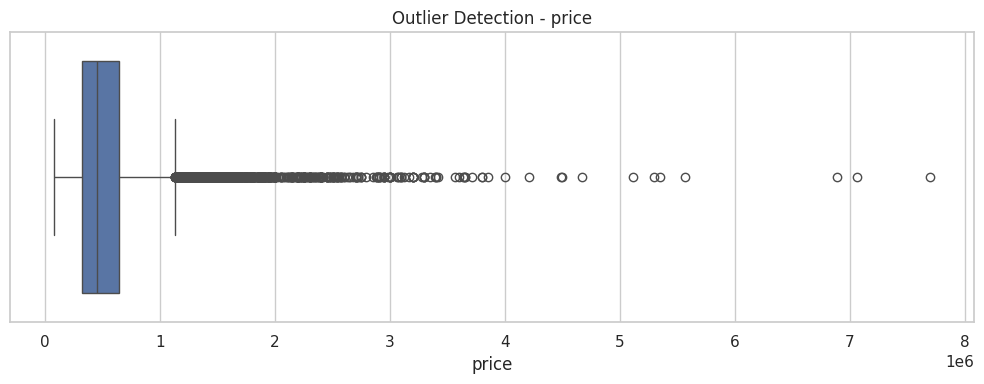

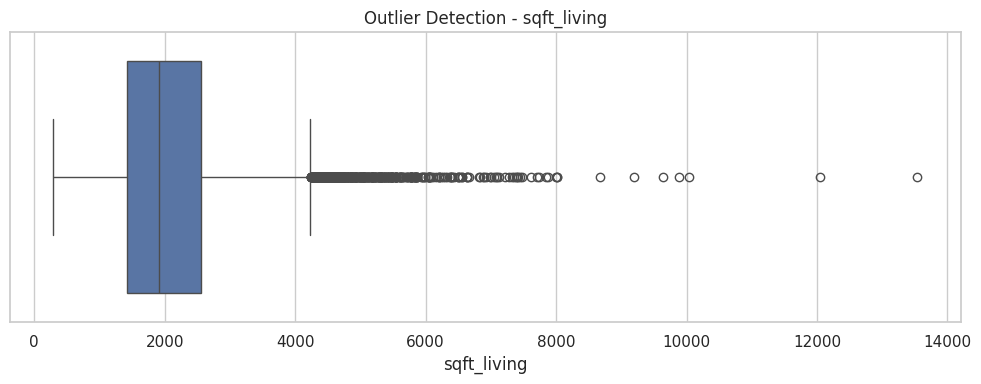

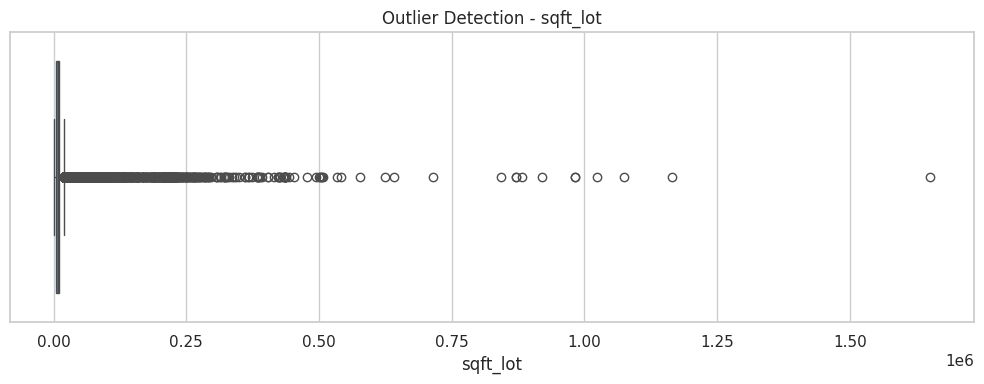

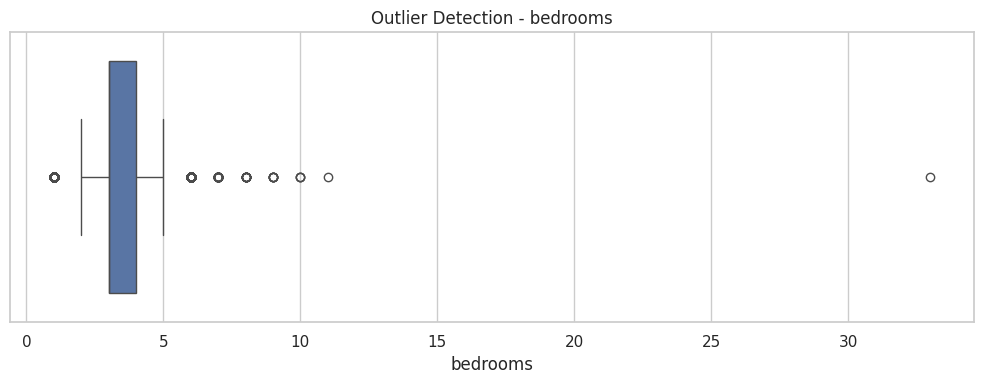

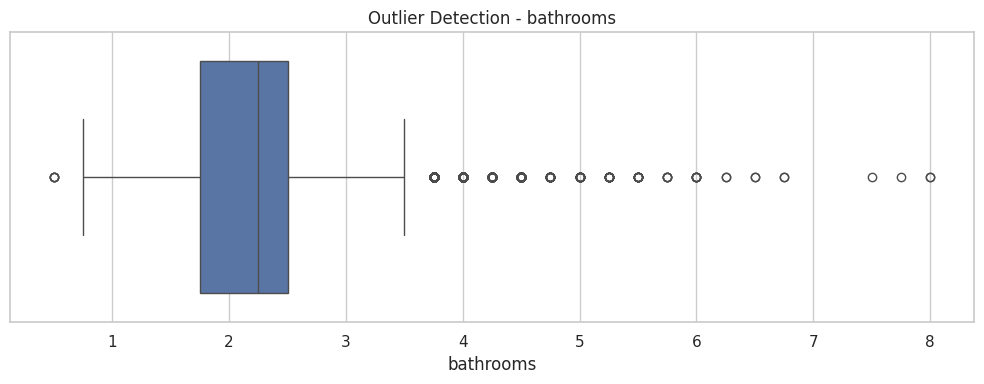

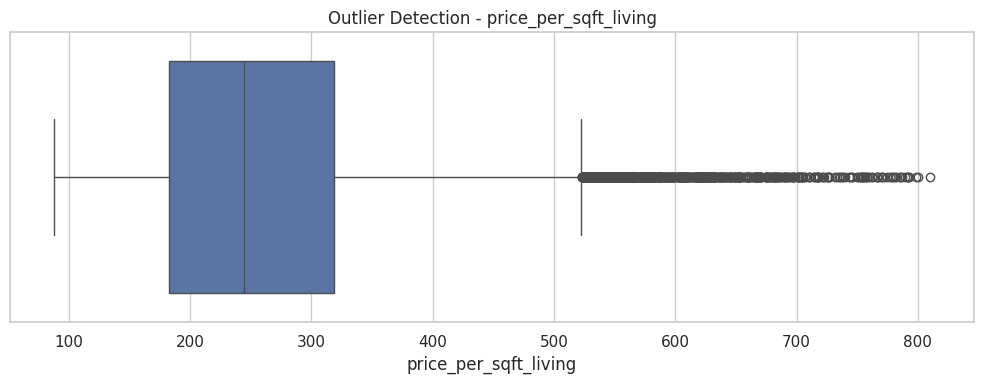

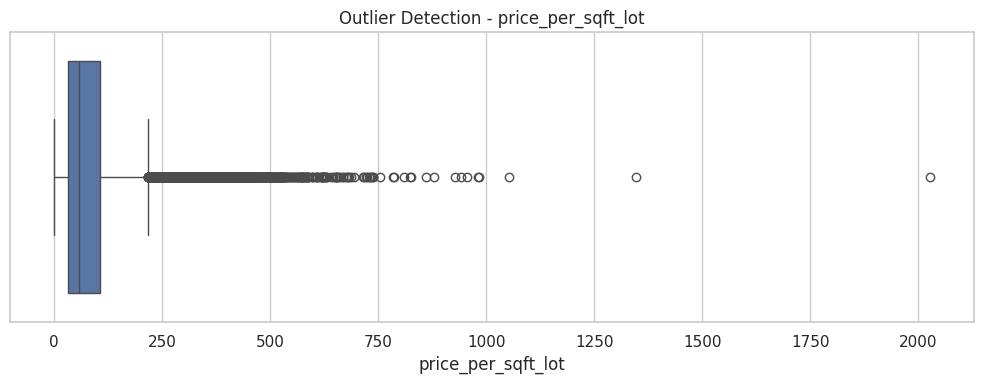

In [44]:
for column in outlier_columns:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=df[column]
    )

    plt.title(f"Outlier Detection - {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

Step 20: Generate property age and renovation summaries

In [45]:
age_summary = (
    df.groupby("property_age_category", observed=False)
    .agg(
        Average_Price=("price", "mean"),
        Median_Price=("price", "median"),
        House_Count=("id", "count")
    )
    .round(2)
)

display(age_summary)

,Average_Price,Median_Price,House_Count
property_age_category,,,
New,615793.02,504129.0,3444
Recent,598983.37,497000.0,3747
Middle Aged,493083.01,425000.0,5909
Old,500633.66,423000.0,7489
Very Old,631701.99,550000.0,1012


In [46]:
renovation_summary = (
    df.groupby("is_renovated")
    .agg(
        Average_Price=("price", "mean"),
        Median_Price=("price", "median"),
        Average_Price_Per_Sqft=(
            "price_per_sqft_living",
            "mean"
        ),
        House_Count=("id", "count")
    )
    .round(2)
)

display(renovation_summary)

,Average_Price,Median_Price,Average_Price_Per_Sqft,House_Count
is_renovated,,,,
0,530360.82,448000.0,261.72,20699
1,760379.03,600000.0,319.30,914


Step 21: Export the cleaned dataset and reports

In [47]:
os.makedirs("data", exist_ok=True)
os.makedirs("reports", exist_ok=True)

In [51]:
df.to_csv(
    "house_sales_cleaned.csv",
    index=False
)

print("Cleaned dataset exported.")

Cleaned dataset exported.


In [49]:
summary_statistics.to_csv(
    "reports/house_sales_summary_statistics.csv"
)

outlier_summary.to_csv(
    "reports/house_sales_outlier_summary.csv",
    index=False
)
renovation_summary.to_csv(
    "reports/renovation_summary.csv"
)

In [50]:
feature_columns = [
    "id",
    "date",
    "sale_year",
    "sale_month",
    "price",
    "yr_built",
    "property_age",
    "yr_renovated",
    "is_renovated",
    "years_since_renovation",
    "sqft_living",
    "sqft_lot",
    "price_per_sqft_living",
    "price_per_sqft_lot",
    "total_rooms",
    "living_lot_ratio"
]

feature_columns = [
    column for column in feature_columns
    if column in df.columns
]

df[feature_columns].to_csv(
    "reports/house_sales_engineered_features.csv",
    index=False
)

print("All reports exported successfully!")

All reports exported successfully!
